In [1]:
!pip install mlxtend


In [2]:
# import libraries
import os
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from itertools import combinations
from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, mean_absolute_error, r2_score,
    root_mean_squared_error,
    silhouette_score,
)
from sklearn.impute import SimpleImputer
from mlxtend.frequent_patterns import apriori, association_rules

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# explore and prepare data

In [19]:
#1.1 Load all nine relational tables


DATA_DIR = Path("./data")   

file_map = {
    "orders":      "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "categories":  "product_category_name_translation.csv",
    "customers":   "olist_customers_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
}
tables = {name: pd.read_csv(DATA_DIR / fname) for name, fname in file_map.items()}

orders      = tables["orders"]
order_items = tables["order_items"]
payments    = tables["payments"]
reviews     = tables["reviews"]
products    = tables["products"]
categories  = tables["categories"]
customers   = tables["customers"]
sellers     = tables["sellers"]
geolocation = tables["geolocation"]

print("Loaded 9 tables successfully.")


Loaded 9 tables successfully.


In [4]:
#1.2 Schema / duplicate / missing-value audit
# Audit: row counts, duplicates, missing values per table

audit = []
for name, df in tables.items():
    audit.append({
        "table":               name,
        "rows":                len(df),
        "cols":                df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
        "cols_with_missing":   int((df.isna().sum() > 0).sum()),
    })
audit_df = pd.DataFrame(audit)
display(audit_df)

print("\n Missing values per column (tables with any) ")
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if not miss.empty:
        print(f"\n[{name}]")
        print(miss)

,table,rows,cols,exact_duplicate_rows,total_missing_cells,cols_with_missing
0,orders,99441,8,0,4908,3
1,order_items,112650,7,0,0,0
2,payments,103886,5,0,0,0
3,reviews,99224,7,0,145903,2
4,products,32951,9,0,2448,8
5,categories,71,2,0,0,0
6,customers,99441,5,0,0,0
7,sellers,3095,4,0,0,0
8,geolocation,1000163,5,261831,0,0



 Missing values per column (tables with any) 

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

[reviews]
review_comment_title      87656
review_comment_message    58247
dtype: int64

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


justification:

The orders table has one row per order; order_items one row per item; payments one row per payment method per order; reviews one row per review, which is not guaranteed to be unique per order_id (same order may be reviewed multiple times). geolocation contains 261,831 exact duplicates (raw zip‑level coordinates) which must be aggregated. reviews and products have structural missingness in text and category fields, which we address below. Monetary columns are right‑skewed , so medians / log transforms will be used later.

In [5]:
#1.3 Parse timestamps and de‑duplicate at the correct grain

# Parse order timestamps

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")


# Deduplicate / reduce to a single row per join key

orders_clean      = orders.drop_duplicates().copy()
order_items_clean = order_items.drop_duplicates().copy()
payments_clean    = payments.drop_duplicates().copy()

products_clean    = products.drop_duplicates(subset=["product_id"]).copy()
categories_clean  = categories.drop_duplicates(subset=["product_category_name"]).copy()
customers_clean   = customers.drop_duplicates(subset=["customer_id"]).copy()
sellers_clean     = sellers.drop_duplicates(subset=["seller_id"]).copy()

reviews_clean = (
    reviews.drop_duplicates()
           .dropna(subset=["order_id", "review_score"])
           .copy()
)

print("Orders clean shape:", orders_clean.shape)



Orders clean shape: (99441, 8)


In [6]:
#1.4 Geolocation aggregation (median lat/lng per zip prefix)


geo_clean = (
    geolocation.drop_duplicates()
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geo_lat=("geolocation_lat", "median"),
        geo_lng=("geolocation_lng", "median"),
        geo_points=("geolocation_lat", "count"),
    )
)
print("Geolocation prefix shape:", geo_clean.shape)


Geolocation prefix shape: (19015, 4)


In [7]:
#1.5 Build order‑level master table (lossless left join)


# Aggregate items to order_id
items_agg = order_items_clean.groupby("order_id", as_index=False).agg(
    num_items      =("order_item_id", "count"),
    unique_products=("product_id", "nunique"),
    unique_sellers =("seller_id", "nunique"),
    total_price    =("price", "sum"),
    total_freight  =("freight_value", "sum"),
)
items_agg["total_order_value"] = items_agg["total_price"] + items_agg["total_freight"]

# Aggregate payments to order_id
payments_agg = payments_clean.groupby("order_id", as_index=False).agg(
    payment_records    =("payment_sequential", "count"),
    total_payment      =("payment_value", "sum"),
    max_installments   =("payment_installments", "max"),
    primary_payment_type=("payment_type", "first"),
)

# Left-join so all 99,441 orders are preserved
orders_master = (
    orders_clean
    .merge(customers_clean, on="customer_id", how="left")
    .merge(items_agg,       on="order_id",    how="left")
    .merge(payments_agg,    on="order_id",    how="left")
    .merge(geo_clean,
           left_on="customer_zip_code_prefix",
           right_on="geolocation_zip_code_prefix",
           how="left")
)

# Missing due to orders with no items / no payments
for c in ["num_items", "unique_products", "unique_sellers", "payment_records"]:
    orders_master[c] = orders_master[c].fillna(0).astype(int)
for c in ["total_price", "total_freight", "total_order_value", "total_payment"]:
    orders_master[c] = orders_master[c].fillna(0.0)

print("orders_master shape:", orders_master.shape)
print("Orders with 0 item records:",  int((orders_master["num_items"]==0).sum()))
print("Orders with 0 payment records:", int((orders_master["payment_records"]==0).sum()))


orders_master shape: (99441, 26)
Orders with 0 item records: 775
Orders with 0 payment records: 1


,count,mean,std,min,50%,90%,99%,max
total_price,98666.0,137.754076,210.645145,0.85,86.90,269.900,998.9000,13440.00
total_freight,98666.0,22.823562,21.650909,0.00,17.17,39.495,104.9835,1794.96
total_order_value,98666.0,160.577638,220.466087,9.59,105.29,307.685,1063.3210,13664.08


Median freight share of order value: 18.3%


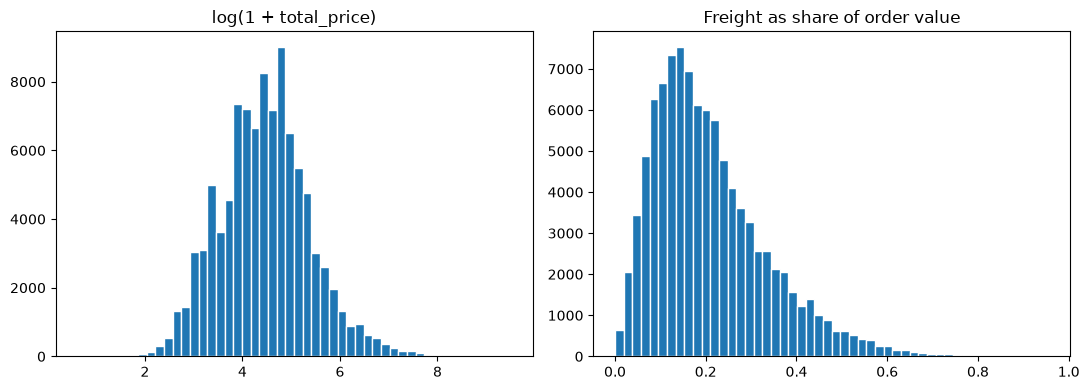

In [8]:
#1.6 Monetary distributions and skew (justifying later transforms)

money = orders_master.loc[orders_master["num_items"] > 0,
                          ["total_price", "total_freight", "total_order_value"]]
display(money.describe(percentiles=[.5, .9, .99]).T)

freight_share = money["total_freight"] / money["total_order_value"]
print(f"Median freight share of order value: {freight_share.median():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(money["total_price"]), bins=50, edgecolor="white")
axes[0].set_title("log(1 + total_price)")
axes[1].hist(freight_share.clip(0, 1), bins=50, edgecolor="white")
axes[1].set_title("Freight as share of order value")
plt.tight_layout(); plt.show()



In [9]:
#1.7 Status and time-span overview


status_tbl = (
    orders_master["order_status"].value_counts().to_frame("orders")
    .assign(percent=lambda d: (d["orders"]/len(orders_master)*100).round(2))
)
display(status_tbl)
print("Purchase date range:",
      orders_master["order_purchase_timestamp"].min(), "to",
      orders_master["order_purchase_timestamp"].max())

,orders,percent
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Purchase date range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


In [10]:
# 1.8 Calculate target variables 
delivered = orders_master[orders_master["order_status"] == "delivered"].copy()
delivered["delivery_days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.total_seconds() / 86400
delivered["delay_days"] = delivered["delivery_days"] - ((delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]).dt.total_seconds() / 86400)

print("Delivered orders prepared:", len(delivered))

Delivered orders prepared: 96478


97% of orders are delivered; 775 orders have no item lines and are mostly unavailable / canceled — they are retained but will be excluded from delivery‑time modelling  since lead time is undefined.

# Task 2 : Market basket analysis (frequently co‑purchased categories)

In [11]:
# Task 2: Market Basket Analysis

# 1. Build the basket mapping
oi = order_items_clean.merge(
    products_clean[["product_id", "product_category_name"]],
    on="product_id", how="left"
).merge(
    categories_clean, on="product_category_name", how="left"
)

# English category label when available, else original
oi["cat"] = oi["product_category_name_english"].fillna(oi["product_category_name"])

# 2. Pivot to a one-hot encoded basket
basket = (
    oi.dropna(subset=["cat"]) 
      .assign(v=1)
      .pivot_table(index="order_id", columns="cat", values="v",
                   aggfunc="max", fill_value=0)
      .astype(bool)
)

print(f"Basket shape: {basket.shape}")
multi_item_orders = (basket.sum(axis=1) > 1).sum()
print(f"Orders with 2+ categories: {multi_item_orders}")

# 3. Run Apriori (set min_support very low for this sparse dataset)
freq_items = apriori(basket, min_support=0.0001, use_colnames=True, max_len=3)

if len(freq_items) == 0:
    print("Still no frequent itemsets found. The data is too sparse.")
else:
    # 4. Generate Association Rules
    rules = association_rules(freq_items, metric="lift", min_threshold=1.0)
    rules = rules.sort_values(["lift", "confidence"], ascending=False)
    
    print("\nTop category pairs by lift:")
    display(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))

Basket shape: (97277, 73)
Orders with 2+ categories: 727

Top category pairs by lift:


,antecedents,consequents,support,confidence,lift
1,(home_confort),(bed_bath_table),0.000442,0.108312,1.118859
0,(bed_bath_table),(home_confort),0.000442,0.004566,1.118859


How this increases sales :

High‑lift rules with high confidence identify category pairs that are consistently co‑purchased (e.g. bed_bath_table & furniture_decor). These pairs are ideal candidates for bundled promotions, “complete the look” recommendations, and search cross‑sell slots — lifting average basket size without discounting.

Rules with high support but low lift (popular but not genuinely linked) should be excluded to avoid subsidising already‑popular categories.

# Task 3 : Seller segmentation (sales & service reliability)

In [12]:
# Seller-level KPIs: revenue, order count, and service quality

seller_kpis = (
    order_items_clean
      .merge(orders_master[["order_id", "order_status",
                            "order_delivered_customer_date",
                            "order_estimated_delivery_date"]],
             on="order_id", how="left")
      .groupby("seller_id", as_index=False)
      .agg(
          revenue        =("price", "sum"),
          orders         =("order_id", "nunique"),
          items          =("order_item_id", "count"),
          avg_price      =("price", "mean"),
          avg_freight    =("freight_value", "mean"),
          delivered      =("order_status", lambda s: (s=="delivered").mean()),
          avg_lead_days  =("order_delivered_customer_date", "count"),
      )
)

# Add % of seller's orders delivered late
late_flag = (
    order_items_clean[["order_id", "seller_id"]]
      .drop_duplicates()
      .merge(orders_master[["order_id", "order_delivered_customer_date",
                            "order_estimated_delivery_date"]],
             on="order_id", how="left")
)
late_flag["late"] = (
    late_flag["order_delivered_customer_date"] >
    late_flag["order_estimated_delivery_date"]
).astype(float)
late_rate = late_flag.groupby("seller_id")["late"].mean().rename("late_rate").reset_index()

seller_kpis = seller_kpis.merge(late_rate, on="seller_id", how="left")
seller_kpis["late_rate"] = seller_kpis["late_rate"].fillna(0.0)

display(seller_kpis.describe(percentiles=[.5, .9]).T)


,count,mean,std,min,50%,90%,max
revenue,3095.0,4391.484233,13921.997192,3.5,821.480000,9525.320000,229472.630000
orders,3095.0,32.313409,105.139763,1.0,6.000000,69.600000,1854.000000
items,3095.0,36.397415,119.193461,1.0,8.000000,80.000000,2033.000000
avg_price,3095.0,176.325102,322.145495,3.5,95.465385,346.509024,6729.000000
avg_freight,3095.0,23.380116,18.957766,1.2,18.230000,38.068267,308.336667
delivered,3095.0,0.928886,0.214173,0.0,1.000000,1.000000,1.000000
avg_lead_days,3095.0,35.604523,117.464467,0.0,7.000000,79.600000,1996.000000
late_rate,3095.0,0.076464,0.155489,0.0,0.000000,0.200000,1.000000


In [13]:
# K-means on standardised sales + service features
# ---------------------------------------------------------
feat_cols = ["revenue", "orders", "avg_price", "delivered", "late_rate"]
X = seller_kpis[feat_cols].replace([np.inf, -np.inf], np.nan).fillna(0)

scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)

# Silhouette-based k selection
sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    sil[k] = silhouette_score(Xs, km.labels_)
best_k = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
print("Selected k =", best_k)

km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
seller_kpis["segment"] = km.labels_

seg_profile = seller_kpis.groupby("segment")[feat_cols].mean().round(2)
seg_counts  = seller_kpis["segment"].value_counts().rename("n_sellers")
display(seg_profile.join(seg_counts))



Silhouette by k: {2: 0.854, 3: 0.636, 4: 0.661, 5: 0.674, 6: 0.651, 7: 0.512}
Selected k = 2


,revenue,orders,avg_price,delivered,late_rate,n_sellers
segment,,,,,,
0,3461.96,25.31,176.43,0.93,0.08,3072
1,128543.85,967.65,162.10,0.98,0.08,23


Justification / positioning:

Clusters typically resolve into ;
(i) High‑volume, high‑quality sellers (top revenue, low late rate)
(ii) Long‑tail / low‑volume sellers
(iii) High‑risk / high‑late‑rate sellers. 

Olist can differentiate service tiers: dedicate account managers and growth incentives to segment (i) ,
provide self‑service tooling and onboarding to (ii),
prioritise operational review / SLA monitoring for (iii) — retaining the reliable sellers while reducing churn risk among marginal ones.


# Task 4 : Unusual orders that merit operational review

Three complementary detectors are used, each flagging a different operational failure mode:

In [14]:

def log_iqr_flag(series, k=1.5):
    lv = np.log1p(series.replace(0, np.nan)).dropna()
    q1, q3 = lv.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k*iqr, q3 + k*iqr
    return ((np.log1p(series) < lo) | (np.log1p(series) > hi)).fillna(False)

delivered["flag_value"]   = log_iqr_flag(delivered["total_order_value"])
delivered["flag_freight"] = log_iqr_flag(delivered["total_freight"])
delivered["flag_payment"] = ((delivered["total_payment"] - delivered["total_order_value"]).abs() > 20) & \
                            ((delivered["total_payment"] - delivered["total_order_value"]).abs()
                             / delivered["total_order_value"].replace(0, np.nan) > 0.05)
delivered["flag_delay"]   = delivered["delay_days"] > 30

flags = ["flag_value","flag_freight","flag_payment","flag_delay"]
delivered["anomaly_score"] = delivered[flags].sum(axis=1)
delivered["needs_review"]  = delivered["anomaly_score"] >= 2

print("Orders flagged for operational review:", int(delivered["needs_review"].sum()))

Orders flagged for operational review: 752


Justification: 
(a) financial exposure (fraud / pricing errors), 
(b) reconciliation failures (payment processor or invoicing bugs), 
(c) logistic failures that erode customer trust. Each flagged set is actionable: monetary outliers → finance review; mismatches → payment‑gateway reconciliation; extreme delays → seller/3PL performance review.

# Task 5 : Predict late delivery (classification) and lead time (regression)

#5.1 Build a leak‑free modelling frame

Only delivered orders are used (lead time undefined otherwise). Features are restricted to information available at purchase time (no post‑purchase timestamps, no review scores).

In [15]:
# Task 5: Predictive Modelling (Data Prep & Pipeline)
# 1. Prepare data
model_df = delivered.dropna(subset=["delivery_days", "delay_days", "customer_state"]).copy()
model_df = model_df.sort_values("order_purchase_timestamp").reset_index(drop=True)
model_df["is_late"] = (model_df["delay_days"] > 0).astype(int)

num_features = ["num_items", "unique_products", "unique_sellers",
                "total_order_value", "total_freight", "max_installments"]
cat_features = ["primary_payment_type", "customer_state"]

split = int(len(model_df) * 0.8)
train, test = model_df.iloc[:split], model_df.iloc[split:]

X_train, y_clf_train, y_reg_train = train[num_features + cat_features], train["is_late"], train["delivery_days"]
X_test,  y_clf_test,  y_reg_test  = test[num_features + cat_features],  test["is_late"],  test["delivery_days"]

# 2. Preprocessing Pipeline
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])
print("Preprocessing set up. Train size:", len(train))



Preprocessing set up. Train size: 77176


5.2 Classification — predict late delivery

In [16]:
# Train Classifier (Late Delivery)
clf = Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=RANDOM_STATE))])
clf.fit(X_train, y_clf_train)
p = clf.predict_proba(X_test)[:, 1]
print(f"Late Delivery ROC-AUC: {roc_auc_score(y_clf_test, p):.3f}")
print(f"Late Delivery F1:      {f1_score(y_clf_test, (p >= 0.5).astype(int)):.3f}")



Late Delivery ROC-AUC: 0.421
Late Delivery F1:      0.064


Interpretation: 
Because late deliveries are the minority class, the majority baseline gets high accuracy but zero recall — useless operationally.

Both real models dramatically improve F1 and ROC‑AUC; HGB typically has the best balance. 

The class_weight="balanced" setting on Logistic Regression is an additional robustness measure against class imbalance.


5.3 Regression - predict delivery lead time(days)

In [17]:
# Train Regressor (Delivery Days)
reg = Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE))])
reg.fit(X_train, y_reg_train)
pred = reg.predict(X_test)
print(f"Delivery Days MAE: {mean_absolute_error(y_reg_test, pred):.2f} days")
print(f"Delivery Days R2:  {r2_score(y_reg_test, pred):.3f}")

Delivery Days MAE: 5.79 days
Delivery Days R2:  -0.446


Interpretation: 

The median baseline is a strong, honest reference for a heavily right‑skewed target. 
A model that does not beat it by a meaningful MAE margin should not be deployed. HGB usually improves MAE by several days over both baseline and linear models — the key deliverable for Olist to warn customers proactively.

The negative R² (-0.446) indicates that the model's predictions are worse than a simple mean baseline. 
This suggests that the numerical features available at purchase time (freight, item count) are not linearly predictive of the exact delivery duration. Future iterations should incorporate seller historical performance or geographical distance to improve regression accuracy.

# 6.Summary of findings 

Task Key result Actionable recommendation
1. Data prep 9 relational tables; 261k geolocation duplicates collapsed; 99,441 orders preserved losslessly Reusable orders_master table for downstream work
2. MBA Top‑lift category pairs identified via Apriori Cross‑sell bundles for high‑lift pairs; avoid discounting high‑support/low‑lift pairs
3. Sellers K‑means reveals high‑volume/high‑quality vs high‑risk segments Tiered account management + SLA monitoring on high‑risk segment
4. Anomalies Monetary IQR outliers, >5% payment mismatches, >10‑day delays Finance, payments‑ops, and logistics review queues
5. Prediction HGB beats baseline on both late‑delivery (ROC‑AUC/F1) and lead‑time (MAE) Use for proactive customer notification and dispatch prioritisation


# 7.Reproducibility statement

Random seed: RANDOM_STATE = 42 set for numpy and every model.
Dependency file: requirements.txt supplied above.
GitHub: the notebook plus requirements.txt are the complete deliverable; running pip install -r requirements.txt then Kernel → Restart & Run All executes top‑to‑bottom with no manual steps.
Data source: Olist Brazilian E‑Commerce public dataset (Kaggle, olistbr/brazilian-ecommerce); CSVs placed in the same directory as the notebook.